# 2 · The detector that can't say why

An Isolation Forest trained on normal flight: it detects, but its score cannot attribute cause.
See [Lesson 2](../docs/lessons/02-the-detector-that-cannot-say-why.md).

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from fdicps import plotting
from fdicps.dual_anomaly_data_generation.parameters import load_sensor_parameters

plotting.use_style()
P = load_sensor_parameters()

In [2]:
from sklearn.metrics import roc_auc_score

from fdicps.baseline_anomaly_detection.detector import BaselineDetector
from fdicps.dual_anomaly_data_generation.scenarios import generate_dataset

train, test = generate_dataset(range(600)), generate_dataset(range(10_000, 10_300))
det = BaselineDetector(n_estimators=150).fit(train.values[train.label == 0], P)
score = det.score(test.values, P)
anomalous = test.label > 0
print("AUC normal vs anomalous:", round(roc_auc_score(anomalous, score), 3))
print("AUC of the score for 'attack, not fault':", round(roc_auc_score(test.label[anomalous] == 2, score[anomalous]), 3))

AUC normal vs anomalous: 0.836
AUC of the score for 'attack, not fault': 0.165


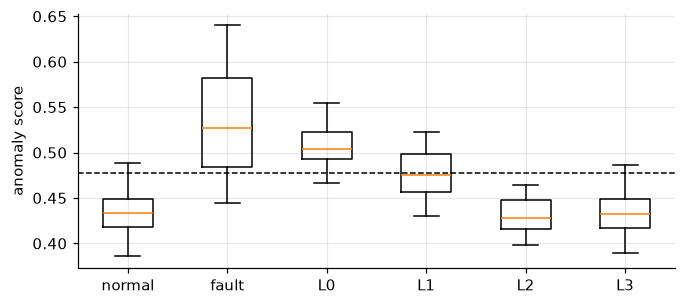

In [3]:
groups = ["normal", "fault"] + [f"L{k}" for k in range(4)]
data = [score[test.label == 0], score[test.label == 1]] + [
    score[(test.label == 2) & (test.level == k)] for k in range(4)
]
fig, ax = plt.subplots(figsize=(7, 3))
ax.boxplot(data, tick_labels=groups, showfliers=False)
ax.axhline(det.threshold, color="k", ls="--", lw=1)
ax.set_ylabel("anomaly score");